# 수렴점 기반 인접 신뢰구간 겹침 실험

각 데이터셋에 원 논문의 중단 규칙을 적용해 데이터셋별 `k_stop`을 찾은 뒤, 해당 시점의 누적 평균과 95% 신뢰구간을 민감도만큼 아래로 이동한 가상 인접 데이터베이스와 비교한다.

- 신뢰구간 상대폭: `W / abs(cumulative_mean)`
- 중단 조건: 상대폭 `< threshold`가 `streak_required`회 연속
- 인접 구간: 원본 수렴점의 동일한 절대폭을 유지하고 중심만 `-delta` 이동
- 겹침 비율: `overlap_width / original_ci_width`

이 겹침 비율은 예산 설정을 위한 분석 지표이며, DP 보장 자체를 대체하지 않는다.

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy import stats

# 논문용 기본 스타일
plt.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 300,
    "font.size": 10, "axes.titlesize": 12, "axes.labelsize": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.22,
})

ALPHA = 0.05
DEFAULT_EPS = 0.5
DEFAULT_THRESHOLD = 0.01
DEFAULT_STREAK = 5
MAXQ = 500

# 환경에 맞게 수정
DATASETS = {
    "CardBase": {"path": Path("data/CardBase.csv"), "column": "Credit_Limit", "format": "csv"},
    "Bank": {"path": Path("data/bank_exp.parquet"), "column": "credit_limit", "format": "parquet"},
}

OUTPUT_DIR = Path("outputs/dp_overlap")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
def load_numeric_dataset(path, column):
    path = Path(path)
    if path.suffix.lower() == ".csv":
        df = pd.read_csv(path)
    elif path.suffix.lower() == ".parquet":
        df = pd.read_parquet(path)
    else:
        raise ValueError(f"지원하지 않는 파일 형식: {path}")
    if column not in df.columns:
        raise KeyError(f"{path}에 '{column}' 열이 없습니다. 실제 열: {list(df.columns)}")
    x = pd.to_numeric(df[column], errors="coerce").dropna().to_numpy(float)
    if x.size == 0:
        raise ValueError(f"{path}의 '{column}' 열에 유효한 숫자가 없습니다.")
    return df, x

def dataset_summary(name, path, column):
    _, x = load_numeric_dataset(path, column)
    n = x.size
    delta = (x.max() - x.min()) / n  # 원 논문의 평균 질의 민감도
    return {"dataset": name, "x": x, "n": n, "true_mean": x.mean(),
            "min": x.min(), "max": x.max(), "delta": delta}

DATA = {name: dataset_summary(name, cfg["path"], cfg["column"])
        for name, cfg in DATASETS.items()}

pd.DataFrame([{k:v for k,v in d.items() if k != "x"} for d in DATA.values()])

,dataset,n,true_mean,min,max,delta
0,CardBase,500,252614.000000,2000.0,899000.0,1794.000000
1,Bank,6744,9074.479537,1439.0,34516.0,4.904656


In [3]:
def run_until_convergence(center, delta, eps=DEFAULT_EPS, threshold=DEFAULT_THRESHOLD,
                          streak_required=DEFAULT_STREAK, maxq=MAXQ, seed=0):
    """원 논문 방식으로 1회씩 질의하고 최초 수렴점에서 중단한다."""
    if eps <= 0 or threshold <= 0 or streak_required < 1 or maxq < 2:
        raise ValueError("eps>0, threshold>0, streak_required>=1, maxq>=2가 필요합니다.")
    rng = np.random.default_rng(seed)
    b = delta / eps
    values, rows = [], []
    streak = 0
    stop = None

    for k in range(1, maxq + 1):
        response = float(center + rng.laplace(0.0, b))
        values.append(response)
        arr = np.asarray(values)
        mean = float(arr.mean())
        if k < 2:
            std = se = moe = ci_lo = ci_hi = width = relw = np.nan
            hit = False
        else:
            std = float(arr.std(ddof=1))
            se = std / np.sqrt(k)
            moe = float(stats.t.ppf(1 - ALPHA/2, k-1) * se)
            ci_lo, ci_hi = mean - moe, mean + moe
            width = 2 * moe
            relw = width / abs(mean) if mean != 0 else np.inf
            hit = bool(relw < threshold)
        streak = streak + 1 if hit else 0
        rows.append({"k": k, "response": response, "mean": mean, "std": std,
                     "se": se, "moe": moe, "ci_lo": ci_lo, "ci_hi": ci_hi,
                     "width": width, "relw": relw, "streak": streak, "hit": hit})
        if streak >= streak_required:
            stop = k
            break

    history = pd.DataFrame(rows)
    if stop is None:
        raise RuntimeError(f"maxq={maxq}회 안에 수렴하지 않았습니다.")
    final = history.iloc[-1].to_dict()
    final.update({"k_stop": int(stop), "eps": eps, "threshold": threshold,
                  "streak_required": streak_required, "delta": delta,
                  "laplace_scale": b, "true_mean": center,
                  "eps_total": eps * stop,
                  "converged": True})
    return history, final

def interval_overlap(ci_lo, ci_hi, adj_lo, adj_hi):
    lo, hi = max(ci_lo, adj_lo), min(ci_hi, adj_hi)
    overlap = max(0.0, hi - lo)
    width = ci_hi - ci_lo
    return {"overlap_lo": lo, "overlap_hi": hi, "overlap_width": overlap,
            "overlap_ratio": overlap / width if width > 0 else np.nan,
            "center_distance": abs(ci_lo - adj_lo)}

def add_adjacent_result(final):
    # 최대값 레코드가 제거되는 방향: 원본 수렴점의 중심과 CI를 -delta만큼 이동
    shift = -final["delta"]
    out = dict(final)
    out["adj_center"] = final["mean"] + shift
    out["adj_ci_lo"] = final["ci_lo"] + shift
    out["adj_ci_hi"] = final["ci_hi"] + shift
    out.update(interval_overlap(final["ci_lo"], final["ci_hi"],
                                out["adj_ci_lo"], out["adj_ci_hi"]))
    out["width_to_delta"] = final["width"] / final["delta"] if final["delta"] else np.inf
    out["delta_to_width"] = final["delta"] / final["width"] if final["width"] else np.inf
    return out

In [4]:
# 단일 조건 실행: 데이터셋별 k_stop은 자동으로 달라진다.
def run_condition(data, eps=DEFAULT_EPS, threshold=DEFAULT_THRESHOLD,
                  streak_required=DEFAULT_STREAK, maxq=MAXQ, seed=0):
    history, final = run_until_convergence(
        center=data["true_mean"], delta=data["delta"], eps=eps,
        threshold=threshold, streak_required=streak_required,
        maxq=maxq, seed=seed)
    return history, add_adjacent_result(final)

# 사용 예시
# histories, finals = {}, {}
# for i, (name, data) in enumerate(DATA.items()):
#     histories[name], finals[name] = run_condition(data, eps=0.5, threshold=0.01, streak_required=5, seed=2026+i)
# pd.DataFrame(finals).T[["k_stop", "mean", "true_mean", "width", "relw", "delta", "overlap_ratio"]]

## 실제 응답값 + 원본/인접 신뢰구간

* 상단은 질의가 누적되며 상대폭이 임계값에 도달하는 과정, 
* 하단은 수렴 시점의 실제 응답값과 두 신뢰구간을 함께 표시
* 인접 구간은 원본 수렴점의 동일한 절대폭을 유지한 채 중심만 `-delta`만큼 이동한다.

In [5]:
def plot_convergence_and_overlap(name, history, final, save=None):
    fig, (ax0, ax1) = plt.subplots(2, 1, figsize=(11, 7.4),
                                   gridspec_kw={"height_ratios": [1.25, 1]},
                                   constrained_layout=True)
    blue, orange, green, purple, gray = "#2166ac", "#d6604d", "#1a9850", "#762a83", "#555555"

    # 1) 수렴 궤적
    h = history[history["k"] >= 2]
    ax0.plot(history["k"], history["mean"], color=blue, lw=1.8, label="Cumulative mean")
    ax0.scatter(history["k"], history["response"], s=18, color=gray, alpha=.62, label="Noisy responses")
    ax0.fill_between(h["k"], h["ci_lo"], h["ci_hi"], color=blue, alpha=.13, label="95% CI")
    ax0.axhline(final["true_mean"], color=green, ls="--", lw=1.5, label="True mean")
    ax0.axvline(final["k_stop"], color="black", ls=":", lw=1.4, label=f"Stop k={final['k_stop']}")
    ax0.set_title(f"{name}: convergence trajectory")
    ax0.set_xlabel("Query count (k)"); ax0.set_ylabel("Query output")
    ax0.legend(ncol=4, loc="best", frameon=False)

    # 2) 수렴점 interval plot
    y_resp = np.zeros(len(history)) + .02 * np.sin(np.arange(len(history)) * 2.4)
    ax1.scatter(history["response"], y_resp, s=28, color=gray, alpha=.7, zorder=3)
    ax1.axvline(final["true_mean"], color=green, ls="--", lw=1.5, label="True mean")
    ax1.plot([final["ci_lo"], final["ci_hi"]], [0.62, 0.62], color=blue, lw=8,
             solid_capstyle="round", label="Original 95% CI")
    ax1.plot([final["adj_ci_lo"], final["adj_ci_hi"]], [0.35, 0.35], color=orange, lw=8,
             solid_capstyle="round", label="Shifted adjacent 95% CI")
    if final["overlap_width"] > 0:
        ax1.plot([final["overlap_lo"], final["overlap_hi"]], [0.485, 0.485], color=purple, lw=10,
                 solid_capstyle="round", label="CI overlap")
    ax1.axvline(final["mean"], color=blue, ls="-", lw=1.2, alpha=.85)
    ax1.axvline(final["adj_center"], color=orange, ls="-", lw=1.2, alpha=.85)
    mid = (final["mean"] + final["adj_center"]) / 2
    ax1.annotate("", xy=(final["adj_center"], .86), xytext=(final["mean"], .86),
                 arrowprops=dict(arrowstyle="<->", color="black", lw=1.2))
    ax1.text(mid, .89, f"Δ={final['delta']:,.1f}", ha="center", va="bottom", fontsize=9)
    ax1.set_yticks([0, .35, .485, .62, .86])
    ax1.set_yticklabels(["Responses", "Adjacent CI", "Overlap", "Original CI", "Centers"])
    ax1.set_xlabel("Query output")
    ax1.set_title("Stopping-point interval comparison")
    ax1.set_ylim(-.12, 1.02)
    ax1.legend(ncol=3, loc="upper left", bbox_to_anchor=(0, -0.22), frameon=False)
    text = (f"ε={final['eps']} | threshold={final['threshold']} | streak={final['streak_required']}\n"
            f"k_stop={final['k_stop']} | ε_total={final['eps_total']:.2f} | "
            f"width={final['width']:,.1f} | relw={final['relw']:.4f}\n"
            f"overlap ratio={final['overlap_ratio']:.3f} | width/Δ={final['width_to_delta']:.3f}")
    ax1.text(1.0, 1.02, text, transform=ax1.transAxes, ha="right", va="bottom", fontsize=9,
             bbox=dict(boxstyle="round,pad=.35", facecolor="white", edgecolor="#bbbbbb"))
    if save:
        fig.savefig(save, bbox_inches="tight")
    plt.show()
    return fig

# 실행 예시
# for name in finals:
#     plot_convergence_and_overlap(name, histories[name], finals[name], OUTPUT_DIR / f"main_{name}.png")

## 조건 스윕: 데이터셋별 겹침 비율 비교

각 조건에서 다시 원 논문 방식으로 중단점을 찾는다. 따라서 `k_stop`도 조건과 데이터셋에 따라 달라진다. 

반복 시행의 평균과 95% 범위를 point-range로 표시해 단일 실행의 우연성을 줄인다.

In [ ]:
# 데이터셋
#  ├─ ε = 0.5
#  │   ├─ threshold = 0.01, streak = 3 → 30회 반복
#  │   ├─ threshold = 0.01, streak = 5 → 30회 반복
#  │   ├─ threshold = 0.03, streak = 3 → 30회 반복
#  │   └─ ...
#  ├─ ε = 0.75
#  │   └─ 같은 조합들을 각각 30회 반복
#  └─ ...

> 하나의 조건 조합마다 랜덤 시드만 바꾸어 30회 반복하고, 각 반복에서 원 논문 방식으로 수렴점 k_stop을 찾은 뒤,다음 값을 저장

- k_stop
- 수렴 시점의 신뢰구간 절대폭/상대폭
- 민감도
- 원본 신뢰구간과 민감도만큼 이동한 인접 신뢰구간의 겹침 비율

> 그 후 plot_sweep_point_ranges()는 그 결과 중 특정 조건만 골라서 비교

예를 들어, Copyplot_sweep_point_ranges(summary, eps=0.5, streak=5)를 실행하면:
- ε=0.5 고정
- streak=5 고정
- threshold만 0.01, 0.03, 0.05로 변경
- 각 threshold마다 30회 반복한 결과를 평균과 표준편차로 요약
- CardBase와 Bank의 결과를 비교

> 그런데, 현재 단계에서 먼저 필요한 것은 다음과 같은 완전히 동일한 조건에서의 반복 비교

In [ ]:
def sweep_conditions(data_dict, epsilons=(0.5, .75, 1.0, 1.25),
                     thresholds=(.01, .03, .05), streaks=(3, 5, 7),
                     reps=30, maxq=MAXQ, seed0=1000):
    rows = []
    for di, (name, data) in enumerate(data_dict.items()):
        for eps in epsilons:
            for threshold in thresholds:
                for streak in streaks:
                    for rep in range(reps):
                        seed = seed0 + di*10_000_000 + int(eps*100)*100_000 + int(threshold*1000)*100 + streak*10 + rep
                        try:
                            _, final = run_condition(data, eps, threshold, streak, maxq, seed)
                            rows.append({"dataset": name, "eps": eps, "threshold": threshold,
                                         "streak": streak, "rep": rep, **final})
                        except RuntimeError:
                            rows.append({"dataset": name, "eps": eps, "threshold": threshold,
                                         "streak": streak, "rep": rep, "converged": False})
    return pd.DataFrame(rows)

def summarize_sweep(raw):
    ok = raw[raw.get("converged", True) == True].copy()
    return (ok.groupby(["dataset", "eps", "threshold", "streak"], as_index=False)
            .agg(k_stop_mean=("k_stop", "mean"), k_stop_sd=("k_stop", "std"),
                 overlap_mean=("overlap_ratio", "mean"), overlap_sd=("overlap_ratio", "std"),
                 width_mean=("width", "mean"), width_sd=("width", "std"),
                 relw_mean=("relw", "mean"), delta=("delta", "first"),
                 convergence_rate=("converged", "mean")))

### 조건 sweep 실험 시각화 함수

In [ ]:
def plot_sweep_point_ranges(summary, eps=None, streak=5, save=None):
    d = summary[summary["streak"] == streak].copy()
    if eps is not None: d = d[d["eps"] == eps]
    if d.empty: raise ValueError("선택한 조건의 결과가 없습니다.")
    thresholds = sorted(d["threshold"].unique())
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
    colors = {name: c for name, c in zip(sorted(d.dataset.unique()), ["#2166ac", "#d6604d", "#1a9850", "#762a83"])}
    for ax, metric, sd, title, ylabel in [(axes[0], "overlap_mean", "overlap_sd", "CI overlap ratio", "Overlap ratio"),
                                           (axes[1], "k_stop_mean", "k_stop_sd", "Convergence point", "k_stop")]:
        for name, g in d.groupby("dataset"):
            g = g.sort_values("threshold")
            ax.errorbar(g["threshold"], g[metric], yerr=g[sd], marker="o", lw=1.8, capsize=3,
                        color=colors[name], label=name)
        ax.set_xscale("log")
        ax.set_xticks(thresholds, [str(x) for x in thresholds])
        ax.set_xlabel("Relative-width threshold")
        ax.set_ylabel(ylabel); ax.set_title(title); ax.grid(alpha=.25)
        ax.legend(frameon=False)
    subtitle = f"streak={streak}" + (f", eps={eps}" if eps is not None else "")
    fig.suptitle(f"Stopping-point comparison ({subtitle})", y=1.03)
    if save: fig.savefig(save, bbox_inches="tight")
    plt.show()
    return fig

실행 예시

```python
histories, finals = {}, {}
for i, (name, data) in enumerate(DATA.items()):
    histories[name], finals[name] = run_condition(
        data, eps=0.5, threshold=0.01, streak_required=5, seed=2026+i
    )

final_table = pd.DataFrame(finals).T
final_table[["k_stop", "true_mean", "mean", "width", "relw", "delta", "overlap_width", "overlap_ratio"]]

for name in finals:
    plot_convergence_and_overlap(
        name, histories[name], finals[name],
        OUTPUT_DIR / f"main_{name}_eps0.5_th0.01_st5.png"
    )

raw = sweep_conditions(DATA, reps=30)
summary = summarize_sweep(raw)
summary.to_csv(OUTPUT_DIR / "sweep_summary.csv", index=False)
plot_sweep_point_ranges(summary, eps=0.5, streak=5,
                        save=OUTPUT_DIR / "sweep_eps0.5_st5.png")
```

## 실험 (단일)

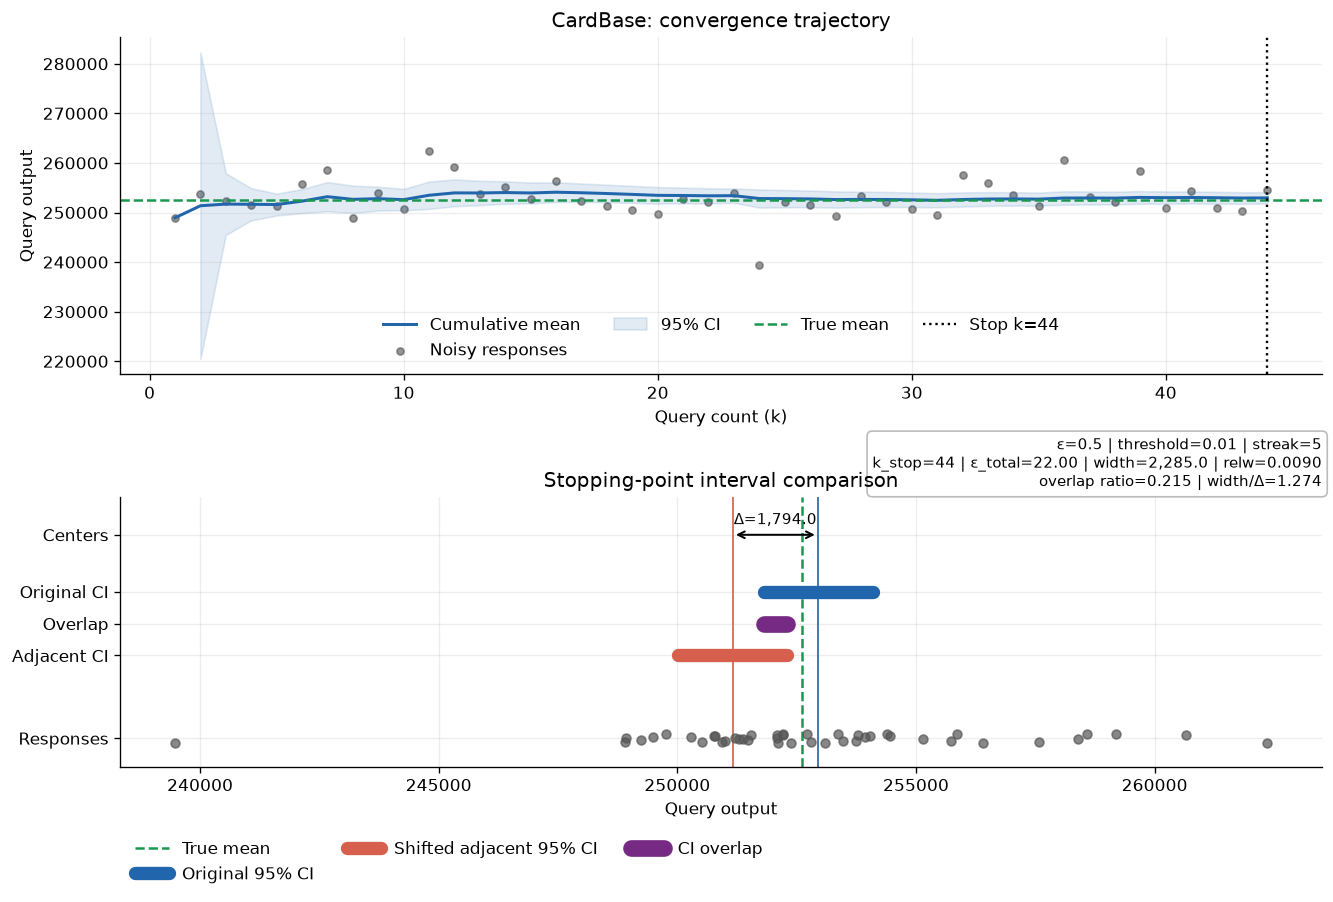

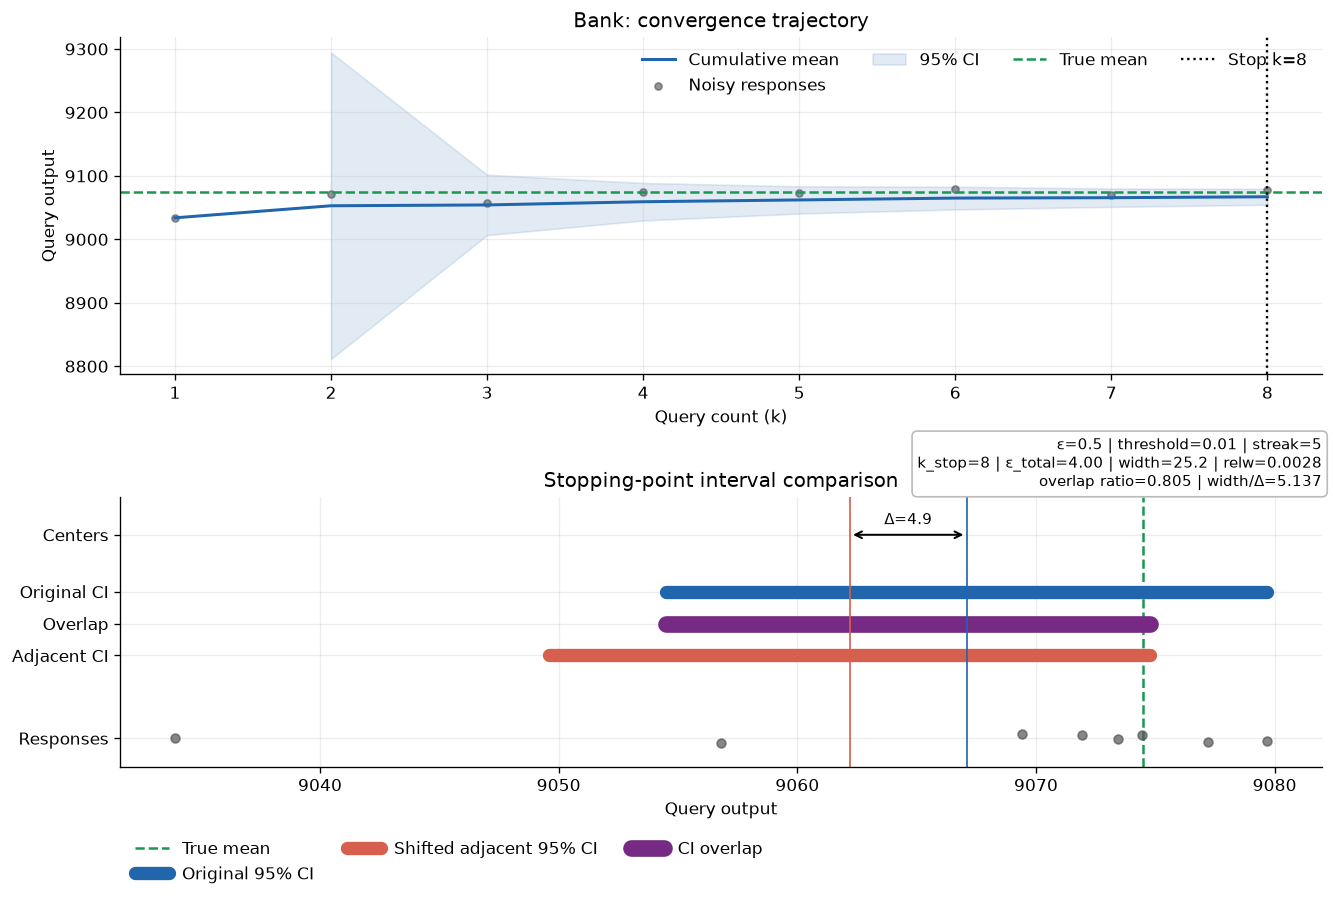

In [ ]:
histories, finals = {}, {}
for i, (name, data) in enumerate(DATA.items()):
    histories[name], finals[name] = run_condition(
        data, eps=0.5, threshold=0.01, streak_required=5, seed=2026+i
    )

final_table = pd.DataFrame(finals).T
final_table[["k_stop", "true_mean", "mean", "width", "relw", "delta", "overlap_width", "overlap_ratio"]]

for name in finals:
    plot_convergence_and_overlap(
        name, histories[name], finals[name],
        OUTPUT_DIR / f"main_{name}_eps0.5_th0.01_st5.png"
    )

# raw = sweep_conditions(DATA, reps=30)
# summary = summarize_sweep(raw)
# summary.to_csv(OUTPUT_DIR / "sweep_summary.csv", index=False)
# plot_sweep_point_ranges(summary, eps=0.5, streak=5,
#                         save=OUTPUT_DIR / "sweep_eps0.5_st5.png")